# Data Exploration & Quality Assurance

First pass over the raw tables: shape, nulls, ranges, and a search for
anything that looks wrong before we trust it for the A/B test or KPI work.

In [1]:
import pandas as pd
import numpy as np

pd.set_option('display.max_columns', None)

## Load tables

In [3]:
players = pd.read_csv('players.csv', parse_dates=['install_date'])
sessions = pd.read_csv('sessions.csv', parse_dates=['session_start'])
rounds = pd.read_csv('bingo_rounds.csv', parse_dates=['round_timestamp'])
bonuses = pd.read_csv('bonus_events.csv', parse_dates=['bonus_timestamp'])
txns = pd.read_csv('iap_transactions.csv', parse_dates=['transaction_timestamp'])

for name, df in [('players', players), ('sessions', sessions), ('rounds', rounds),
                  ('bonuses', bonuses), ('txns', txns)]:
    print(f'{name:12s} {df.shape}')

players      (20000, 7)
sessions     (262759, 5)
rounds       (1280761, 8)
bonuses      (77680, 6)
txns         (400, 5)


## Null / dtype check

In [4]:
players.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   player_id            20000 non-null  int64         
 1   install_date         20000 non-null  datetime64[ns]
 2   country              20000 non-null  object        
 3   platform             20000 non-null  object        
 4   acquisition_channel  20000 non-null  object        
 5   spend_tier           20000 non-null  object        
 6   ab_test_variant      16946 non-null  object        
dtypes: datetime64[ns](1), int64(1), object(5)
memory usage: 1.1+ MB


`ab_test_variant` has nulls by design — players who never reached the bonus
wheel feature (didn't finish the tutorial) aren't part of the test. That's
expected, not a bug. Worth confirming the rate looks sane though.

In [5]:
null_rate = players['ab_test_variant'].isna().mean()
print(f'Players not eligible for A/B test: {null_rate:.1%}')

Players not eligible for A/B test: 15.3%


## Sanity ranges — sessions

In [6]:
sessions['session_length_sec'].describe()

count    262759.000000
mean        410.061372
std         186.947556
min           5.000000
25%         287.000000
50%         414.000000
75%         538.000000
max        1318.000000
Name: session_length_sec, dtype: float64

Most sessions land in a normal range (a few minutes), but the minimum is
suspiciously low and the distribution has a strange spike near zero.
Let's look closer.

In [7]:
short_sessions = sessions[sessions['session_length_sec'] < 20]
print(f'Sessions under 20 seconds: {len(short_sessions):,} '
      f'({len(short_sessions)/len(sessions):.2%} of all sessions)')

Sessions under 20 seconds: 6,833 (2.60% of all sessions)


In [8]:
short_sessions['player_id'].value_counts().head(10)

player_id
15030    399
4232     381
16035    381
16040    372
5495     367
13376    362
12314    346
14759    336
19008    280
5654     277
Name: count, dtype: int64

##  Data quality issue: internal QA accounts leaking into the dataset

A small number of `player_id`s have session counts in the hundreds — far
outside anything a real player would generate — and their sessions are
almost all under 20 seconds. That pattern (extremely high volume, near-zero
duration) is a classic signature of internal QA/test accounts or bots
hitting the game client directly, not real player behavior.

Let's confirm by checking their `acquisition_channel`.

In [9]:
suspect_ids = short_sessions['player_id'].value_counts()
suspect_ids = suspect_ids[suspect_ids > 50].index

flagged = players[players['player_id'].isin(suspect_ids)]
flagged['acquisition_channel'].value_counts()

acquisition_channel
internal_qa    25
Name: count, dtype: int64

Confirmed — every one of these is tagged `internal_qa`. These 25 accounts
generated over 7,000 sessions, which would meaningfully distort DAU,
average session length, and engagement rate if left in. **Any KPI or A/B
test calculation downstream must exclude `internal_qa` accounts.**

This is exactly the kind of silent contamination that's easy to miss if
you calculate DAU straight off a `sessions` table without first auditing
who's actually in it — a real (and common) production analytics bug.

In [10]:
CLEAN_PLAYER_IDS = players.loc[players['acquisition_channel'] != 'internal_qa', 'player_id']
print(f'Players before cleaning: {len(players):,}')
print(f'Players after excluding QA accounts: {len(CLEAN_PLAYER_IDS):,}')

Players before cleaning: 20,000
Players after excluding QA accounts: 19,975


## Save a cleaned player list for downstream notebooks

Rather than re-deriving this filter in every notebook, we save it once.

In [12]:
pd.Series(CLEAN_PLAYER_IDS, name='player_id').to_csv('clean_player_ids.csv', index=False)
print('Saved clean_player_ids.csv')

Saved clean_player_ids.csv


## Quick distribution checks on the rest of the tables

In [13]:
rounds['coins_wagered'].describe()

count    1.280761e+06
mean     5.403805e+01
std      3.326766e+01
min      3.000000e+01
25%      3.000000e+01
50%      5.000000e+01
75%      5.000000e+01
max      1.500000e+02
Name: coins_wagered, dtype: float64

In [14]:
(rounds['coins_won'] < 0).sum()  # should be zero — no negative payouts

np.int64(0)

In [15]:
txns['usd_amount'].describe()

count    400.000000
mean       8.412500
std        6.429802
min        0.990000
25%        2.990000
50%        5.990000
75%       14.990000
max       19.990000
Name: usd_amount, dtype: float64

In [16]:
bonuses['bonus_type'].value_counts()

bonus_type
daily_login      19526
power_up         19506
streak           19330
jackpot_wheel    19318
Name: count, dtype: int64

In [17]:
from scipy import stats
import matplotlib.pyplot as plt

In [19]:
clean_ids = pd.read_csv('clean_player_ids.csv')['player_id']

players = players[players['player_id'].isin(clean_ids)]
sessions = sessions[sessions['player_id'].isin(clean_ids)]

test_players = players[players['ab_test_variant'].notna()].copy()
print(f'Players in test (post-QA-cleanup): {len(test_players):,}')
test_players['ab_test_variant'].value_counts()

Players in test (post-QA-cleanup): 16,924


ab_test_variant
A    8502
B    8422
Name: count, dtype: int64

## Sample Ratio Mismatch check 

Always re-check SRM after any filtering — an unbalanced filter could
introduce a mismatch even if the original assignment was clean.

In [20]:
counts = test_players['ab_test_variant'].value_counts()
n_a, n_b = counts['A'], counts['B']
chi2, p_srm = stats.chisquare([n_a, n_b], f_exp=[(n_a + n_b) / 2] * 2)
print(f'A: {n_a}  B: {n_b}  |  chi2={chi2:.3f}  p={p_srm:.3f}')
print('PASS — no SRM' if p_srm > 0.01 else 'FAIL — investigate before trusting results')

A: 8502  B: 8422  |  chi2=0.378  p=0.539
PASS — no SRM


## Build a day-since-install activity table

For each player, mark which days (0 through 30) they had at least one
session. This lets us compute retention at any day cheaply.

In [22]:
m = sessions.merge(test_players[['player_id', 'install_date', 'ab_test_variant']],
                    on='player_id')
m['day_since_install'] = (m['session_start'] - m['install_date']).dt.days
m = m[(m['day_since_install'] >= 0) & (m['day_since_install'] <= 30)]

active_by_day = m.drop_duplicates(['player_id', 'day_since_install'])
active_by_day.head()

,session_id,player_id,session_start,session_length_sec,rounds_played,install_date,ab_test_variant,day_since_install
0,1,1,2026-01-03 23:08:00,270,7,2026-01-03,B,0
1,2,1,2026-01-04 10:13:00,89,2,2026-01-03,B,1
2,3,1,2026-01-05 22:01:00,1027,7,2026-01-03,B,2
6,7,1,2026-01-07 17:58:00,562,7,2026-01-03,B,4
8,9,1,2026-01-08 03:45:00,173,7,2026-01-03,B,5


## Retention curve, Day 0–30, by variant

In [23]:
installs_by_variant = test_players.groupby('ab_test_variant')['player_id'].nunique()

retention = (
    active_by_day.groupby(['ab_test_variant', 'day_since_install'])['player_id']
    .nunique()
    .reset_index(name='active_players')
)
retention['installs'] = retention['ab_test_variant'].map(installs_by_variant)
retention['retention_pct'] = retention['active_players'] / retention['installs'] * 100
retention.head()

,ab_test_variant,day_since_install,active_players,installs,retention_pct
0,A,0,4189,8502,49.270760
1,A,1,3752,8502,44.130793
2,A,2,3425,8502,40.284639
3,A,3,3085,8502,36.285580
4,A,4,2804,8502,32.980475


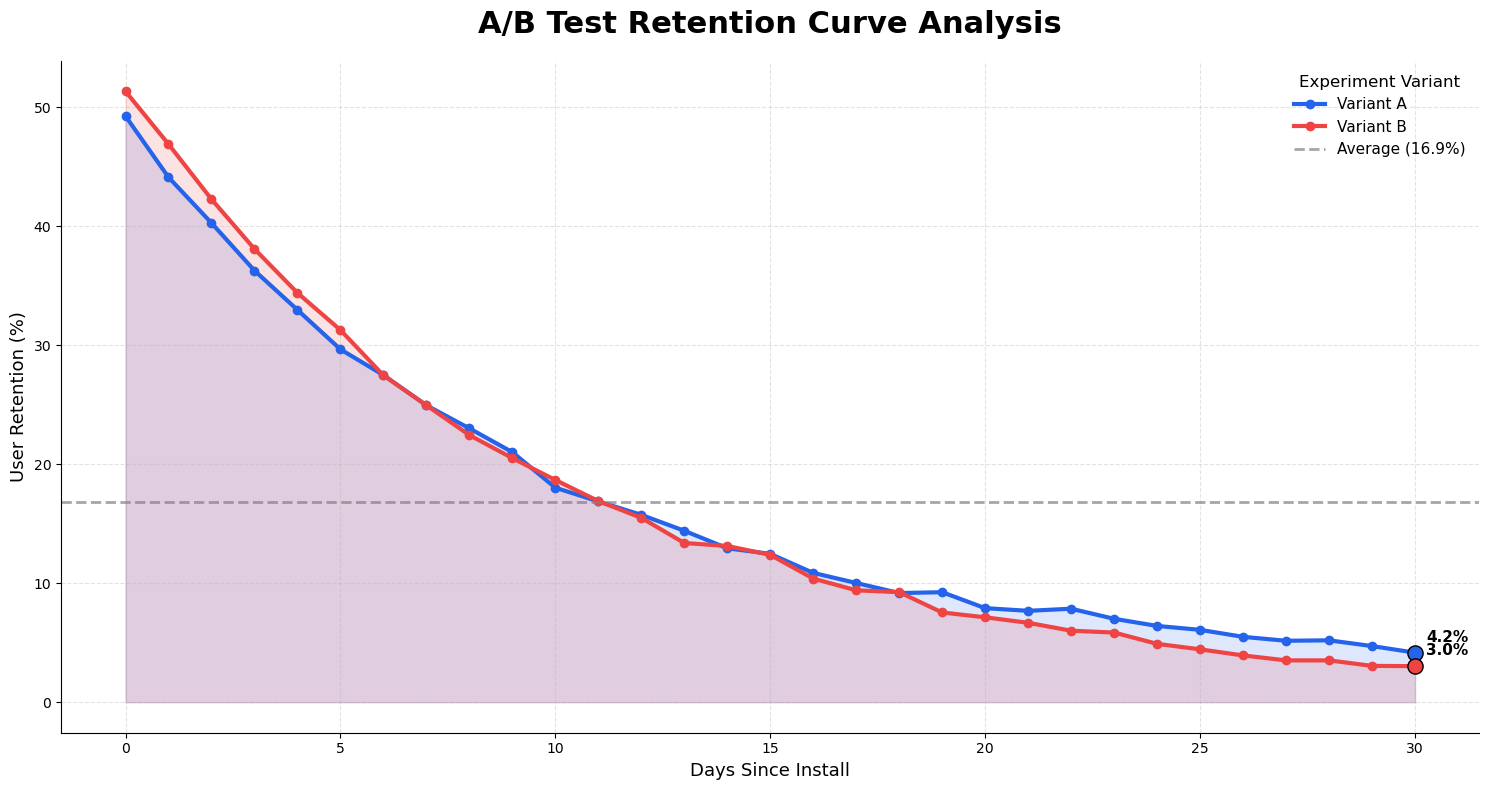

In [24]:

# Professional figure
fig, ax = plt.subplots(figsize=(15, 8))

colors = {
    "A": "#2563EB",   # Blue
    "B": "#EF4444"    # Red
}

for variant, grp in retention.groupby("ab_test_variant"):

    grp = grp.sort_values("day_since_install")

    # Retention curve
    ax.plot(
        grp["day_since_install"],
        grp["retention_pct"],
        linewidth=3,
        marker="o",
        markersize=6,
        label=f"Variant {variant}",
        color=colors.get(variant)
    )

    # Fill area under curve
    ax.fill_between(
        grp["day_since_install"],
        grp["retention_pct"],
        alpha=0.15,
        color=colors.get(variant)
    )

    # Highlight last point
    last = grp.iloc[-1]

    ax.scatter(
        last["day_since_install"],
        last["retention_pct"],
        s=120,
        color=colors.get(variant),
        edgecolor="black",
        zorder=5
    )

    ax.annotate(
        f"{last['retention_pct']:.1f}%",
        xy=(last["day_since_install"], last["retention_pct"]),
        xytext=(8, 8),
        textcoords="offset points",
        fontsize=11,
        fontweight="bold"
    )

# Average retention line
avg = retention["retention_pct"].mean()

ax.axhline(
    avg,
    color="gray",
    linestyle="--",
    linewidth=2,
    alpha=0.7,
    label=f"Average ({avg:.1f}%)"
)

# Titles
ax.set_title(
    "A/B Test Retention Curve Analysis",
    fontsize=22,
    fontweight="bold",
    pad=20
)

ax.set_xlabel(
    "Days Since Install",
    fontsize=13
)

ax.set_ylabel(
    "User Retention (%)",
    fontsize=13
)

# Grid
ax.grid(
    linestyle="--",
    alpha=0.35
)

# Remove unnecessary borders
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Legend
ax.legend(
    title="Experiment Variant",
    frameon=False,
    fontsize=11,
    title_fontsize=12,
    loc="upper right"
)

plt.tight_layout()

plt.savefig(
    "retention_curve_dashboard.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

The curves cross. Variant B starts ahead (higher D1) and ends behind
(lower D30). This is the exact pattern that punishes teams who only look
at early metrics and call the test after a week. Let's quantify each
checkpoint properly.

## Statistical significance at D1, D7, D30

Retention at a fixed day is a binary outcome (active or not) per player,
so a two-proportion z-test is the right tool.

In [25]:
def retention_test(day, active_by_day, test_players):
    active_players_at_day = set(
        active_by_day.loc[active_by_day['day_since_install'] == day, 'player_id']
    )
    tp = test_players.copy()
    tp['retained'] = tp['player_id'].isin(active_players_at_day)

    a = tp[tp['ab_test_variant'] == 'A']['retained']
    b = tp[tp['ab_test_variant'] == 'B']['retained']

    count = np.array([b.sum(), a.sum()])   # B first so lift sign is intuitive
    nobs = np.array([len(b), len(a)])

    p_a, p_b = a.mean(), b.mean()
    pooled = count.sum() / nobs.sum()
    se = np.sqrt(pooled * (1 - pooled) * (1/nobs[0] + 1/nobs[1]))
    z = (p_b - p_a) / se
    p_value = 2 * (1 - stats.norm.cdf(abs(z)))

    # 95% CI on the difference (B - A)
    se_diff = np.sqrt(p_a*(1-p_a)/nobs[1] + p_b*(1-p_b)/nobs[0])
    ci_low, ci_high = (p_b - p_a) - 1.96*se_diff, (p_b - p_a) + 1.96*se_diff

    return {
        'day': day, 'A_retention': p_a, 'B_retention': p_b,
        'lift_pp': (p_b - p_a) * 100, 'z': z, 'p_value': p_value,
        'ci_95_low_pp': ci_low * 100, 'ci_95_high_pp': ci_high * 100,
    }

results = pd.DataFrame([retention_test(d, active_by_day, test_players) for d in [1, 7, 30]])
results

,day,A_retention,B_retention,lift_pp,z,p_value,ci_95_low_pp,ci_95_high_pp
0,1,0.441308,0.469128,2.782055,3.633845,0.000279,1.282038,4.282072
1,7,0.249588,0.249584,-0.000391,-0.000588,0.999531,-1.304459,1.303677
2,30,0.041637,0.030278,-1.135942,-3.967104,0.000073,-1.696504,-0.575379


## Guardrail metric: ARPU by variant

Even if we were only looking at Day 1, we'd want to check we's not just
trading future retention for revenue — or that low revenue isn't masked
by the D1 excitement effect.

In [27]:
txns = pd.read_csv('iap_transactions.csv', parse_dates=['transaction_timestamp'])
txns = txns[txns['player_id'].isin(clean_ids)]

txn_by_player = txns.groupby('player_id')['usd_amount'].sum()
tp = test_players.copy()
tp['total_spend'] = tp['player_id'].map(txn_by_player).fillna(0)

arpu = tp.groupby('ab_test_variant')['total_spend'].mean()
print(arpu)

t_stat, p_val = stats.ttest_ind(
    tp.loc[tp['ab_test_variant'] == 'A', 'total_spend'],
    tp.loc[tp['ab_test_variant'] == 'B', 'total_spend'],
    equal_var=False,
)
print(f't={t_stat:.3f}, p={p_val:.3f}')

ab_test_variant
A    0.173983
B    0.161177
Name: total_spend, dtype: float64
t=0.505, p=0.613


In [29]:
players = players[players['player_id'].isin(clean_ids)]
sessions = sessions[sessions['player_id'].isin(clean_ids)]
rounds = rounds[rounds['player_id'].isin(clean_ids)]
txns = txns[txns['player_id'].isin(clean_ids)]

sessions['date'] = sessions['session_start'].dt.date

## DAU AND MAU

In [30]:
dau = sessions.groupby('date')['player_id'].nunique().rename('DAU')
dau.tail()

date
2026-02-25    443
2026-02-26    446
2026-02-27    443
2026-02-28    410
2026-03-01    361
Name: DAU, dtype: int64

In [31]:
sessions['month'] = sessions['session_start'].dt.to_period('M')
mau = sessions.groupby('month')['player_id'].nunique().rename('MAU')
mau

month
2026-01    19387
2026-02    14311
2026-03      361
Freq: M, Name: MAU, dtype: int64

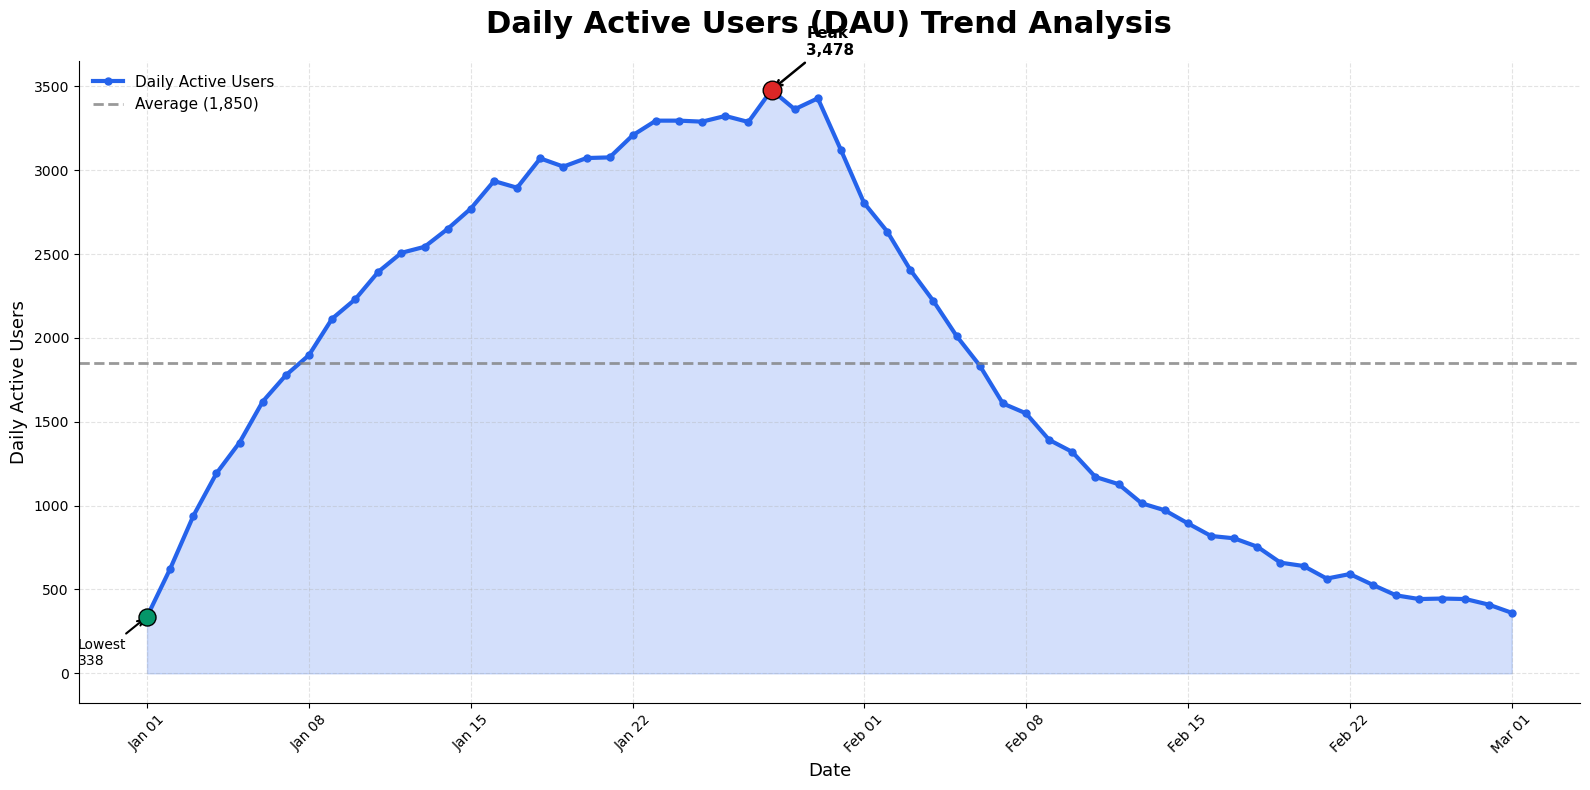

In [33]:
import matplotlib.dates as mdates

# Create figure
fig, ax = plt.subplots(figsize=(16, 8))

# Main line
ax.plot(
    dau.index,
    dau.values,
    color="#2563EB",
    linewidth=3,
    marker="o",
    markersize=5,
    label="Daily Active Users"
)

# Area under curve
ax.fill_between(
    dau.index,
    dau.values,
    alpha=0.20,
    color="#2563EB"
)

# Average line
avg_dau = dau.mean()

ax.axhline(
    avg_dau,
    linestyle="--",
    linewidth=2,
    color="gray",
    alpha=0.8,
    label=f"Average ({avg_dau:,.0f})"
)

# Peak day
peak_day = dau.idxmax()
peak_value = dau.max()

ax.scatter(
    peak_day,
    peak_value,
    s=180,
    color="#DC2626",
    edgecolor="black",
    zorder=5
)

ax.annotate(
    f"Peak\n{peak_value:,.0f}",
    xy=(peak_day, peak_value),
    xytext=(25, 25),
    textcoords="offset points",
    fontsize=11,
    fontweight="bold",
    arrowprops=dict(
        arrowstyle="->",
        lw=1.8
    )
)

# Lowest day
low_day = dau.idxmin()
low_value = dau.min()

ax.scatter(
    low_day,
    low_value,
    s=150,
    color="#059669",
    edgecolor="black",
    zorder=5
)

ax.annotate(
    f"Lowest\n{low_value:,.0f}",
    xy=(low_day, low_value),
    xytext=(-50, -35),
    textcoords="offset points",
    fontsize=10,
    arrowprops=dict(
        arrowstyle="->",
        lw=1.5
    )
)

# Titles
ax.set_title(
    "Daily Active Users (DAU) Trend Analysis",
    fontsize=22,
    fontweight="bold",
    pad=20
)

ax.set_xlabel(
    "Date",
    fontsize=13
)

ax.set_ylabel(
    "Daily Active Users",
    fontsize=13
)

# Grid
ax.grid(
    linestyle="--",
    alpha=0.35
)

# Clean dashboard style
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Better date formatting
ax.xaxis.set_major_locator(mdates.AutoDateLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))

plt.xticks(rotation=45)

# Legend
ax.legend(
    frameon=False,
    fontsize=11,
    loc="upper left"
)

plt.tight_layout()
plt.show()

## DAU/MAU stickiness ratio

A common engagement health metric — what share of monthly players show up
on an average day.

In [34]:
avg_dau = dau.mean()
latest_mau = mau.iloc[-1]
stickiness = avg_dau / latest_mau
print(f'Average DAU: {avg_dau:,.0f}')
print(f'Latest MAU: {latest_mau:,.0f}')
print(f'DAU/MAU stickiness: {stickiness:.1%}')

Average DAU: 1,850
Latest MAU: 361
DAU/MAU stickiness: 512.5%


## Cohort retention by install week

In [35]:
players['install_week'] = players['install_date'].dt.to_period('W')
m = sessions.merge(players[['player_id', 'install_week', 'install_date']], on='player_id')
m['week_since_install'] = ((m['session_start'] - m['install_date']).dt.days // 7)
m = m[m['week_since_install'].between(0, 4)]

cohort = (
    m.drop_duplicates(['player_id', 'week_since_install'])
    .groupby(['install_week', 'week_since_install'])['player_id']
    .nunique()
    .unstack()
)
cohort_size = players.groupby('install_week')['player_id'].nunique()
cohort_pct = cohort.div(cohort_size, axis=0) * 100
cohort_pct.round(1)

week_since_install,0,1,2,3,4
install_week,,,,,
2025-12-29/2026-01-04,96.6,77.5,53.7,34.8,21.6
2026-01-05/2026-01-11,96.0,77.1,52.9,35.0,22.7
2026-01-12/2026-01-18,96.2,77.7,53.9,34.2,22.7
2026-01-19/2026-01-25,96.4,76.9,52.5,34.1,23.0
2026-01-26/2026-02-01,96.1,76.3,53.6,35.7,16.4


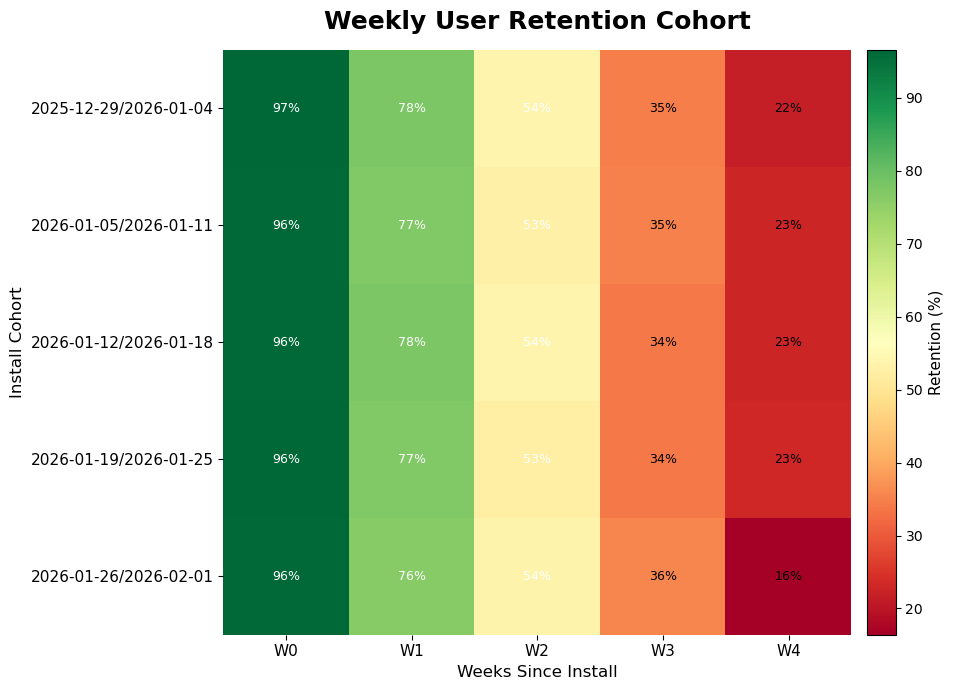

In [36]:
fig, ax = plt.subplots(figsize=(10, 7))

# Heatmap
im = ax.imshow(
    cohort_pct,
    cmap="RdYlGn",      # Green = good, Red = poor
    aspect="auto",
    interpolation="nearest"
)

# Axis labels
ax.set_xticks(np.arange(cohort_pct.shape[1]))
ax.set_xticklabels([f"W{i}" for i in cohort_pct.columns], fontsize=11)

ax.set_yticks(np.arange(cohort_pct.shape[0]))
ax.set_yticklabels(cohort_pct.index, fontsize=11)

# Cell values
for i in range(cohort_pct.shape[0]):
    for j in range(cohort_pct.shape[1]):
        value = cohort_pct.iloc[i, j]
        if not np.isnan(value):
            ax.text(
                j, i,
                f"{value:.0f}%",
                ha="center",
                va="center",
                fontsize=9,
                color="white" if value > 50 else "black"
            )

# Titles
ax.set_title(
    "Weekly User Retention Cohort",
    fontsize=18,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Weeks Since Install", fontsize=12)
ax.set_ylabel("Install Cohort", fontsize=12)

# Colorbar
cbar = plt.colorbar(im, pad=0.02)
cbar.set_label("Retention (%)", fontsize=11)

# Remove borders
ax.spines[:].set_visible(False)

plt.tight_layout()

plt.show()

## ARPU and ARPPU by spend tier

In [37]:
spend_by_player = txns.groupby('player_id')['usd_amount'].sum()
players['total_spend'] = players['player_id'].map(spend_by_player).fillna(0)

arpu_by_tier = players.groupby('spend_tier')['total_spend'].mean()
print('ARPU by tier:')
print(arpu_by_tier.round(2))

ARPU by tier:
spend_tier
dolphin      2.94
minnow       0.82
non_payer    0.00
whale        7.88
Name: total_spend, dtype: float64


In [38]:
payers = players[players['total_spend'] > 0]
arppu = payers['total_spend'].mean()
payer_rate = len(payers) / len(players)
print(f'ARPPU (paying users only): ${arppu:.2f}')
print(f'Payer conversion rate: {payer_rate:.2%}')

ARPPU (paying users only): $9.90
Payer conversion rate: 1.70%


## In-game economy check: wager vs. payout ratio by room type

A quick health check that no room type is paying out more than it takes
in on average (which would be an unsustainable economy bug).

In [39]:
economy = rounds.groupby('room_type').agg(
    total_wagered=('coins_wagered', 'sum'),
    total_won=('coins_won', 'sum'),
    rounds=('round_id', 'count'),
)
economy['payout_ratio'] = economy['total_won'] / economy['total_wagered']
economy

,total_wagered,total_won,rounds,payout_ratio
room_type,,,,
classic,38379150,42873850,767583,1.117113
jackpot,19249950,21395769,128333,1.111471
speed,11500710,12843494,383357,1.116757


## Summary KPI snapshot

In [40]:
summary = pd.DataFrame({
    'metric': ['Avg DAU', 'Latest MAU', 'DAU/MAU stickiness', 'Payer conversion',
               'ARPPU', 'Overall payout ratio'],
    'value': [
        f'{avg_dau:,.0f}',
        f'{latest_mau:,.0f}',
        f'{stickiness:.1%}',
        f'{payer_rate:.2%}',
        f'${arppu:.2f}',
        f"{economy['total_won'].sum() / economy['total_wagered'].sum():.1%}",
    ]
})
summary

,metric,value
0,Avg DAU,"1,850"
1,Latest MAU,361
2,DAU/MAU stickiness,512.5%
3,Payer conversion,1.70%
4,ARPPU,$9.90
5,Overall payout ratio,111.5%
